In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn umap-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import umap.umap_ as umap


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("NPFC-Test_Database_V2.csv")

eeg_features = [
    'Delta_TP9', 'Delta_AF7', 'Delta_AF8', 'Delta_TP10',
    'Theta_TP9', 'Theta_AF7', 'Theta_AF8', 'Theta_TP10',
    'Alpha_TP9', 'Alpha_AF7', 'Alpha_AF8', 'Alpha_TP10',
    'Beta_TP9', 'Beta_AF7', 'Beta_AF8', 'Beta_TP10',
    'Gamma_TP9', 'Gamma_AF7', 'Gamma_AF8', 'Gamma_TP10'
]

physiological_features = [
    'EDA',
    'BVP',
    'Temperature'
]

emotion_features = [
    'resmasknet_anger',
    'resmasknet_disgust',
    'resmasknet_fear',
    'resmasknet_happiness',
    'resmasknet_sadness',
    'resmasknet_surprise',
    'resmasknet_neutral'
]

self_reports = [
    'Selfreport_valence',
    'Selfreport_arousal',
    'Selfreport_focus'
]

# Combine input features
features = (
    eeg_features +
    physiological_features +
    emotion_features
)

# Keep only existing columns
#features = [col for col in features if col in df.columns]

# Select input data
X = df[features].copy()

# Keep concentration labels separately
y_focus = df['Selfreport_focus'].copy()

print("Number of features:", len(features))
print("Features:", features)



Number of features: 30
Features: ['Delta_TP9', 'Delta_AF7', 'Delta_AF8', 'Delta_TP10', 'Theta_TP9', 'Theta_AF7', 'Theta_AF8', 'Theta_TP10', 'Alpha_TP9', 'Alpha_AF7', 'Alpha_AF8', 'Alpha_TP10', 'Beta_TP9', 'Beta_AF7', 'Beta_AF8', 'Beta_TP10', 'Gamma_TP9', 'Gamma_AF7', 'Gamma_AF8', 'Gamma_TP10', 'EDA', 'BVP', 'Temperature', 'resmasknet_anger', 'resmasknet_disgust', 'resmasknet_fear', 'resmasknet_happiness', 'resmasknet_sadness', 'resmasknet_surprise', 'resmasknet_neutral']


In [4]:
# PREPROCESSING

# Convert features to numeric, replacing invalid values with NaN
X = X.apply(pd.to_numeric, errors='coerce')

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that are entirely empty
X = X.dropna(axis=1, how='all')

# Update feature list
features = X.columns.tolist()

# Impute missing values
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nPreprocessed shape:", X_scaled.shape)




Preprocessed shape: (47905, 30)


In [5]:

# =====================================================
# 4. PCA
# =====================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=df.index
)

pca_df['Selfreport_focus'] = y_focus

print("\nPCA Explained Variance:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)
###
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=features
)

print(loadings.sort_values('PC1', key=abs, ascending=False))


PCA Explained Variance:
[0.17676654 0.12098792]
Total explained variance: 0.29775446303876885
                           PC1       PC2
Beta_TP10             0.287366 -0.174064
Beta_TP9              0.279865 -0.171210
Beta_AF7              0.267925  0.349142
Gamma_AF7             0.254779  0.303002
Gamma_TP10            0.250774 -0.133524
Gamma_TP9             0.247482 -0.138084
Alpha_AF7             0.246940  0.369547
Theta_AF7             0.238356  0.358647
Delta_AF7             0.222830  0.345835
Theta_TP9             0.219762 -0.227683
Beta_AF8              0.206511 -0.007484
Theta_TP10            0.204597 -0.239667
Delta_TP9             0.202568 -0.219242
Alpha_TP9             0.191168 -0.207923
Delta_TP10            0.186775 -0.227577
Gamma_AF8             0.182044  0.000958
Alpha_AF8             0.180823  0.000837
Theta_AF8             0.179221  0.014725
Alpha_TP10            0.176999 -0.203644
Delta_AF8             0.141564 -0.026634
resmasknet_surprise   0.088265  0.019325
EDA

In [ ]:
# =====================================================
# 5. UMAP - Comparación de n_neighbors
# =====================================================

import umap
import matplotlib.pyplot as plt
import pandas as pd

for n in (2, 5, 10, 20, 50, 100, 200):

    # Crear y entrenar UMAP
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=n,
        min_dist=0.1,
        metric='euclidean',
        random_state=42
    )

    X_umap = reducer.fit_transform(X_scaled)

    # Crear DataFrame
    umap_df = pd.DataFrame(
        X_umap,
        columns=['UMAP1', 'UMAP2'],
        index=df.index
    )

    umap_df['Selfreport_focus'] = y_focus

    # Visualizar resultados
    plt.figure(figsize=(10, 7))

    scatter = plt.scatter(
        umap_df['UMAP1'],
        umap_df['UMAP2'],
        c=umap_df['Selfreport_focus'],
        cmap='coolwarm',
        alpha=0.7,
        s=15
    )

    plt.colorbar(scatter, label='Selfreport_focus')
    plt.title(f'UMAP - n_neighbors = {n}')
    plt.xlabel('UMAP1')
    plt.ylabel('UMAP2')
    plt.tight_layout()
    plt.show()

/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn

In [41]:

# =====================================================
# 6. t-SNE
# =====================================================

# Perplexity must be smaller than the number of observations
perplexity = min(30, len(X_scaled) - 1)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    learning_rate='auto',
    max_iter=1000,
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=df.index
)

tsne_df['Selfreport_focus'] = y_focus



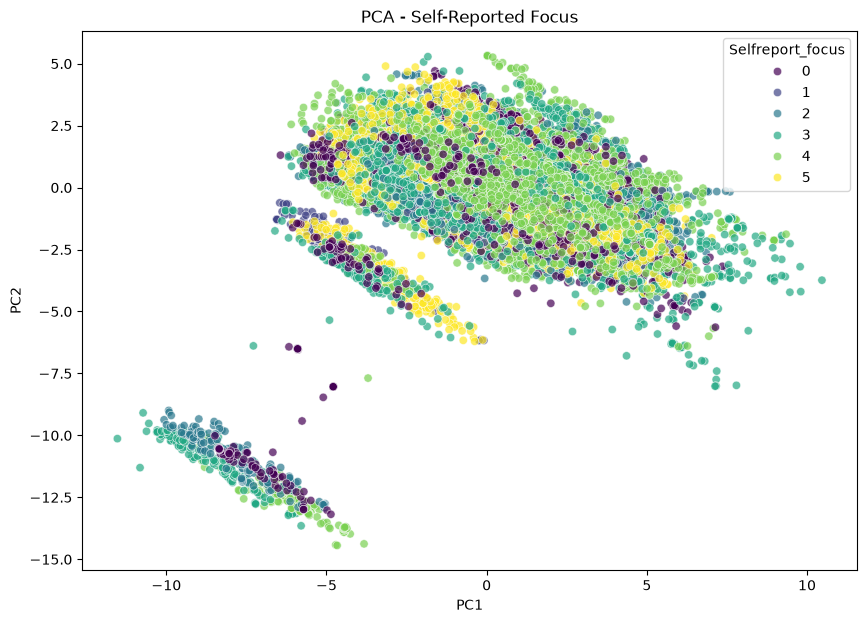

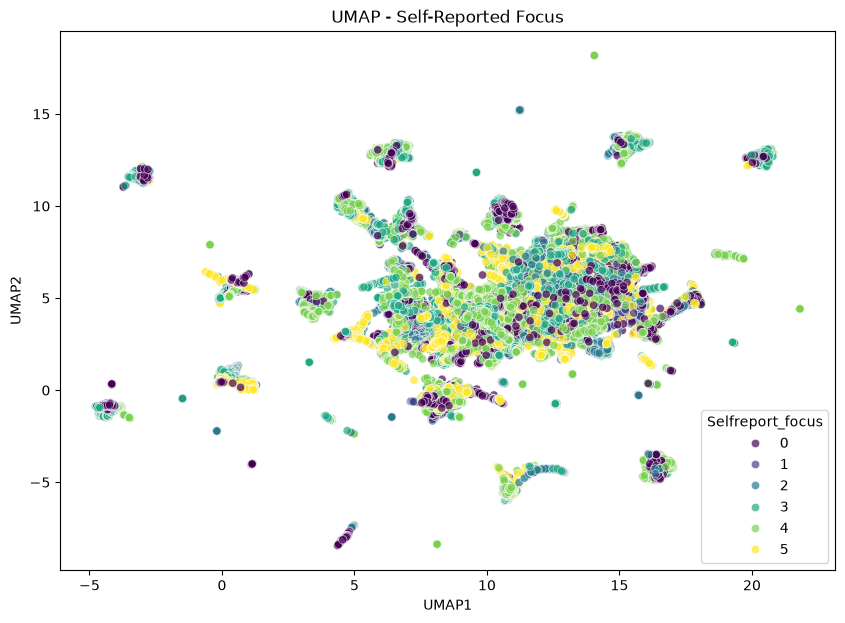

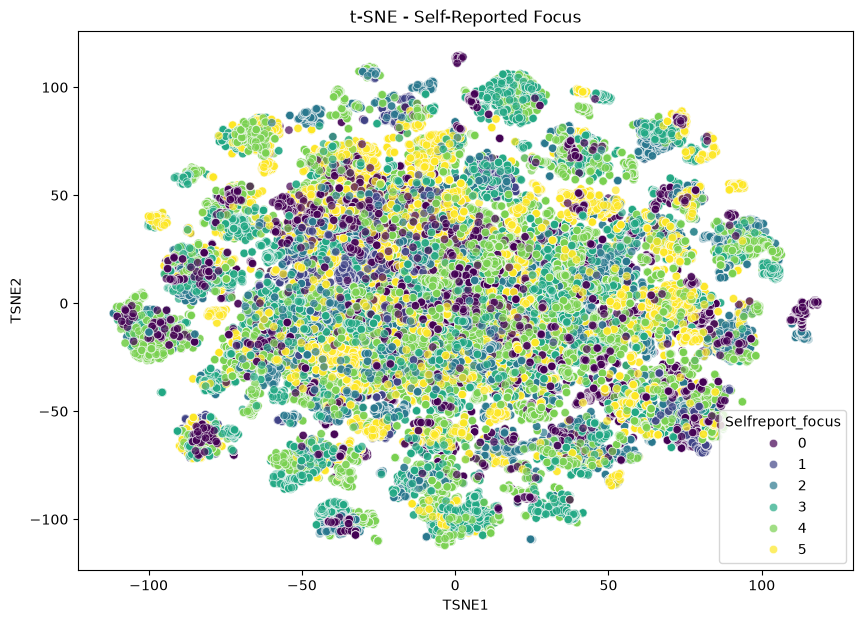

In [45]:

# =====================================================
# 7. VISUALIZATION
# =====================================================

# PCA
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('PCA - Self-Reported Focus')
plt.show()


# UMAP
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=umap_df,
    x='UMAP1',
    y='UMAP2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('UMAP - Self-Reported Focus')
plt.show()


# t-SNE
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x='TSNE1',
    y='TSNE2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('t-SNE - Self-Reported Focus')
plt.show()